# Implementation of classification using decision trees. Application of splitting criteria such as entropy, information gain, and Gini impurity.
**Dataset:** `Social_Network_Ads` 


In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [23]:
df = pd.read_csv("D:\BDA 20\BDA LAB\AIML-BDA-Lab-Work\AssignmentFiles\data\Social_Network_Ads.csv")

print("Shape:", df.shape)
print("\nFirst 5 rows:\n", df.head())

print("\nSummary statistics:\n", df.describe())
print("\nMissing values:\n", df.isnull().sum())



Shape: (400, 5)

First 5 rows:
     User ID  Gender  Age  EstimatedSalary  Purchased
0  15624510    Male   19            19000          0
1  15810944    Male   35            20000          0
2  15668575  Female   26            43000          0
3  15603246  Female   27            57000          0
4  15804002    Male   19            76000          0

Summary statistics:
             User ID         Age  EstimatedSalary   Purchased
count  4.000000e+02  400.000000       400.000000  400.000000
mean   1.569154e+07   37.655000     69742.500000    0.357500
std    7.165832e+04   10.482877     34096.960282    0.479864
min    1.556669e+07   18.000000     15000.000000    0.000000
25%    1.562676e+07   29.750000     43000.000000    0.000000
50%    1.569434e+07   37.000000     70000.000000    0.000000
75%    1.575036e+07   46.000000     88000.000000    1.000000
max    1.581524e+07   60.000000    150000.000000    1.000000

Missing values:
 User ID            0
Gender             0
Age                

<h1>Decision Tree with Visualization

Train accuracy: 0.9133333333333333
Test accuracy : 0.92


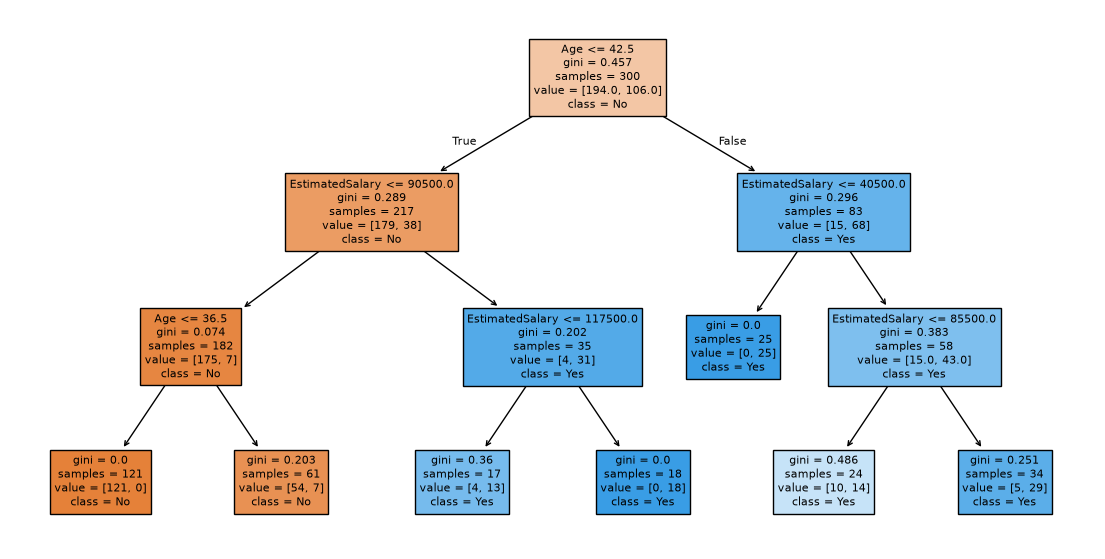

In [24]:
x = df[["Age", "EstimatedSalary"]]
y = df["Purchased"]

X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.25, random_state=42)

tree = DecisionTreeClassifier(max_depth=3, random_state=42)
tree.fit(X_train, y_train)

print("Train accuracy:", tree.score(X_train, y_train))
print("Test accuracy :", accuracy_score(y_test, tree.predict(X_test)))

plt.figure(figsize=(14, 7))
plot_tree(tree, feature_names=X.columns, class_names=["No", "Yes"], filled=True)
plt.show()

<h1>Entroy with IG

In [25]:
# parameters: criterion = entropy (information gain), test_size = 0.20
# dataset = "Social Network Ads"
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.20,
    random_state=45
)

from sklearn.preprocessing import StandardScaler
sc_x = StandardScaler()
x_train = sc_x.fit_transform(x_train)
x_test = sc_x.transform(x_test)

from sklearn.tree import DecisionTreeClassifier
classifier = DecisionTreeClassifier(criterion='entropy', random_state=0)
classifier.fit(x_train, y_train)

y_pred = classifier.predict(x_test)   # predicting y for the testing data

print("Actual: ", y_test.values)
print("Predicted: ", y_pred)

from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred)

print("\n\nTrue Neg ", cm[0][0])
print("False Pos", cm[0][1])
print("False Neg", cm[1][0])
print("True Pos ", cm[1][1])

accuracy = (cm[0][0] + cm[1][1]) / (cm[0][0] + cm[1][1] + cm[1][0] + cm[0][1])
print("\nAccuracy - ", accuracy * 100, "%")

from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

Actual:  [1 1 0 1 0 0 0 0 0 1 0 0 0 1 0 0 0 1 0 0 1 1 0 0 0 0 1 0 1 0 1 0 0 0 0 1 0
 1 0 1 0 1 1 1 0 1 1 1 0 0 0 0 1 1 0 0 1 0 1 1 0 0 1 0 0 1 0 0 0 1 0 0 0 0
 1 1 0 0 1 1]
Predicted:  [0 1 1 1 0 0 0 0 0 1 0 1 0 1 0 0 0 0 0 0 0 1 0 0 0 0 1 0 1 0 1 0 1 1 0 1 0
 1 0 1 0 1 1 0 0 1 1 0 0 0 0 0 1 1 0 0 0 0 1 1 0 0 1 0 0 1 0 0 0 1 0 0 0 0
 1 0 1 0 1 1]


True Neg  43
False Pos 5
False Neg 7
True Pos  25

Accuracy -  85.0 %
              precision    recall  f1-score   support

           0       0.86      0.90      0.88        48
           1       0.83      0.78      0.81        32

    accuracy                           0.85        80
   macro avg       0.85      0.84      0.84        80
weighted avg       0.85      0.85      0.85        80



<h1>Gini Index

In [26]:
# parameters: criterion = gini, test_size = 0.20
# dataset = "Social Network Ads"
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.20,
    random_state=45
)

from sklearn.preprocessing import StandardScaler
sc_x = StandardScaler()
x_train = sc_x.fit_transform(x_train)
x_test = sc_x.transform(x_test)

from sklearn.tree import DecisionTreeClassifier
classifier = DecisionTreeClassifier(criterion='gini', random_state=0)
classifier.fit(x_train, y_train)

y_pred = classifier.predict(x_test)   # predicting y for the testing data

print("Actual: ", y_test.values)
print("Predicted: ", y_pred)

from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred)

print("\n\nTrue Neg ", cm[0][0])
print("False Pos", cm[0][1])
print("False Neg", cm[1][0])
print("True Pos ", cm[1][1])

accuracy = (cm[0][0] + cm[1][1]) / (cm[0][0] + cm[1][1] + cm[1][0] + cm[0][1])
print("\nAccuracy - ", accuracy * 100, "%")

from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

Actual:  [1 1 0 1 0 0 0 0 0 1 0 0 0 1 0 0 0 1 0 0 1 1 0 0 0 0 1 0 1 0 1 0 0 0 0 1 0
 1 0 1 0 1 1 1 0 1 1 1 0 0 0 0 1 1 0 0 1 0 1 1 0 0 1 0 0 1 0 0 0 1 0 0 0 0
 1 1 0 0 1 1]
Predicted:  [0 1 1 1 0 0 0 0 0 1 0 1 0 1 0 0 0 0 0 0 0 1 0 0 0 0 1 0 1 0 0 0 1 1 0 1 0
 1 0 1 0 0 0 0 0 1 1 0 0 0 0 0 1 0 0 0 0 0 1 0 0 0 1 0 0 1 0 0 0 1 0 0 0 0
 1 0 1 0 1 1]


True Neg  43
False Pos 5
False Neg 12
True Pos  20

Accuracy -  78.75 %
              precision    recall  f1-score   support

           0       0.78      0.90      0.83        48
           1       0.80      0.62      0.70        32

    accuracy                           0.79        80
   macro avg       0.79      0.76      0.77        80
weighted avg       0.79      0.79      0.78        80



In [27]:
features = ["Age", "EstimatedSalary"]

for criterion in ["entropy", "gini"]:
    clf = DecisionTreeClassifier(criterion=criterion, random_state=0)
    clf.fit(x_train, y_train)

    t = clf.tree_
    left, right = t.children_left[0], t.children_right[0]

    root = t.impurity[0]
    children = (t.n_node_samples[left] * t.impurity[left] +
                t.n_node_samples[right] * t.impurity[right]) / t.n_node_samples[0]

    f = t.feature[0]
    threshold = t.threshold[0] * sc_x.scale_[f] + sc_x.mean_[f]   # back to original units

    name = "Entropy" if criterion == "entropy" else "Gini"
    gain_name = "Information gain" if criterion == "entropy" else "Gini gain"

    print(f"--- {name} ---")
    print(f"Root split          : {features[f]} <= {threshold:.2f}")
    print(f"{name} of root node : {root:.4f}")
    print(f"Weighted {name} of children: {children:.4f}")
    print(f"{gain_name}         : {root - children:.4f}")
    print("Test accuracy       :", clf.score(x_test, y_test), "\n")

--- Entropy ---
Root split          : Age <= 44.50
Entropy of root node : 0.9312
Weighted Entropy of children: 0.6401
Information gain         : 0.2912
Test accuracy       : 0.85 

--- Gini ---
Root split          : Age <= 44.50
Gini of root node : 0.4531
Weighted Gini of children: 0.2721
Gini gain         : 0.1810
Test accuracy       : 0.7875 

